<a href="https://colab.research.google.com/github/hend-22/-IT326-Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Import Libraries & Load Preprocessed Dataset**

In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score


url= "https://raw.githubusercontent.com/hend-22/-IT326-Project/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)
df.head()


,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,0
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,0
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,1
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,0
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,0


## **Feature Selection**

In [171]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

## **Visual Representation**

Confusion matrices were generated for each partition size to visually evaluate the classifier's performance and to examine the distribution of correct and incorrect predictions before and after class merging. These visualizations helped interpret the model's behavior and assess the effectiveness of the classification process.

# Gini Decision Tree Classification3

In [172]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop('Daily_Stress_Level', axis=1)
y = df['Daily_Stress_Level']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.1,
    random_state=1,
    stratify=y
)

gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model.fit(X_train, y_train)

print("Gini Decision Tree trained successfully!")

Gini Decision Tree trained successfully!


Gini Accuracy (90/10): 0.658


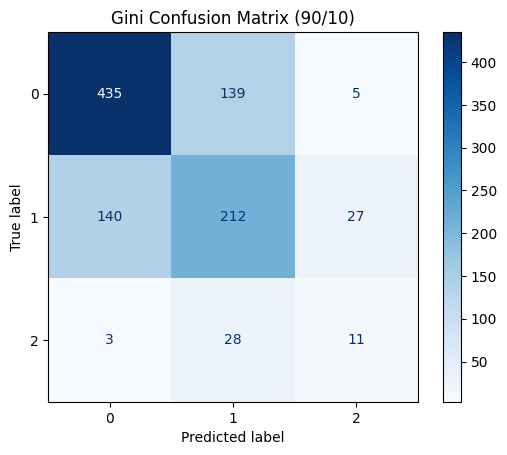

In [173]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = gini_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Gini Accuracy (90/10):", accuracy)

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (90/10)")
plt.show()

### Gini Decision Tree – 90/10 Split


Using the Gini criterion with a 90/10 train-test split, the model achieved **66.4% accuracy**. The confusion matrix shows that the model correctly classified 443 Low, 207 Medium, and 14 High stress cases. However, it identified only 14 out of 42 actual High stress cases, indicating difficulty in predicting this class, possibly due to the imbalance in the dataset.

Gini Accuracy (80/20): 0.652


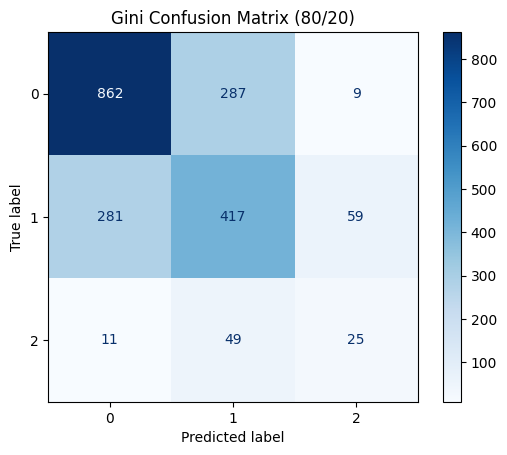

In [174]:
# Gini Decision Tree - 80/20 Split

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

gini_model_80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model_80.fit(X_train_80, y_train_80)

y_pred_80 = gini_model_80.predict(X_test_80)

accuracy_80 = accuracy_score(y_test_80, y_pred_80)

print("Gini Accuracy (80/20):", accuracy_80)

cm_80 = confusion_matrix(y_test_80, y_pred_80)

ConfusionMatrixDisplay(
    confusion_matrix=cm_80,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (80/20)")
plt.show()

### Gini Decision Tree – 80/20 Split

Using the Gini criterion with an 80/20 train-test split, the model achieved **65.2% accuracy**. The confusion matrix shows that 862 Low, 417 Medium, and 25 High stress cases were correctly classified. However, only 25 out of 85 actual High stress cases were identified, showing that the model still struggled with this class. The accuracy was also slightly lower than the 90/10 split.

Gini Accuracy (70/30): 0.656


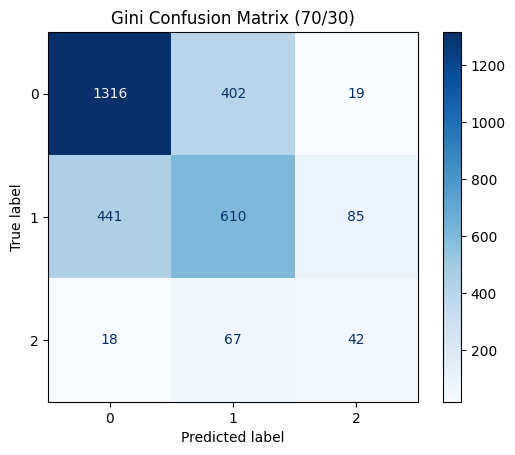

In [175]:
# Gini Decision Tree - 70/30 Split

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X, y,
    test_size=0.3,
    random_state=1,
    stratify=y
)

gini_model_70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model_70.fit(X_train_70, y_train_70)

y_pred_70 = gini_model_70.predict(X_test_70)

accuracy_70 = accuracy_score(y_test_70, y_pred_70)

print("Gini Accuracy (70/30):", accuracy_70)

cm_70 = confusion_matrix(y_test_70, y_pred_70)

ConfusionMatrixDisplay(
    confusion_matrix=cm_70,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (70/30)")
plt.show()

### Gini Decision Tree – 70/30 Split
Using the Gini criterion with a 70/30 split, the model achieved **65.6% accuracy**. It correctly classified 1,316 Low, 610 Medium, and 42 High stress cases. However, only 42 out of 127 High stress cases were correctly identified (33.1%), showing that the model still struggles with this class.

### Gini Decision Tree – Results

The Gini Decision Tree was tested using three train-test splits to compare its performance.

| Train/Test Split | Accuracy | High Stress Recall |
|---|---|---|
| 90/10 | 66.40% | 33.3% |
| 80/20 | 65.2% | 29.4% |
| 70/30 | 65.60% | 33.1% |

The 90/10 split achieved the highest accuracy (66.4%), while the 70/30 split had a slightly lower accuracy (65.6%). All three splits showed difficulty identifying High stress cases, which may be related to the small number of samples in this class.

## **Decision Tree Classification Using Entropy**

The Decision Tree classifier was applied to the dataset using the Entropy criterion (Information Gain) with three different train-test partitions:

90% Training  10% Testing

80% Training  20% Testing

70% Training  30% Testing


**Partition 90/10**

Accuracy: 0.67
Precision: 0.6706018579102548
Recall: 0.67


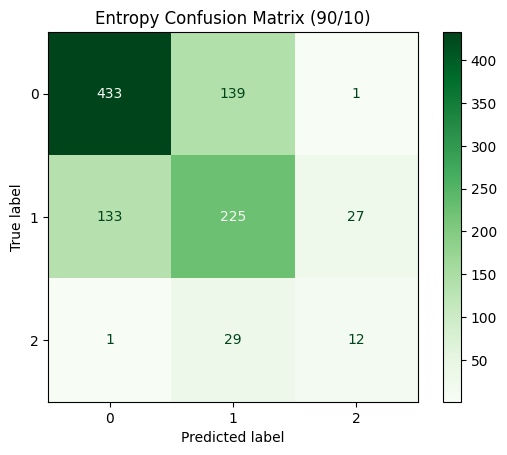

In [176]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))

cn=df['Daily_Stress_Level'].unique()
ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=cn,
    cmap="Greens"
)

plt.title("Entropy Confusion Matrix (90/10)")
plt.show()

**Partition 80/20**

Accuracy: 0.6715
Precision: 0.6708926574728192
Recall: 0.6715


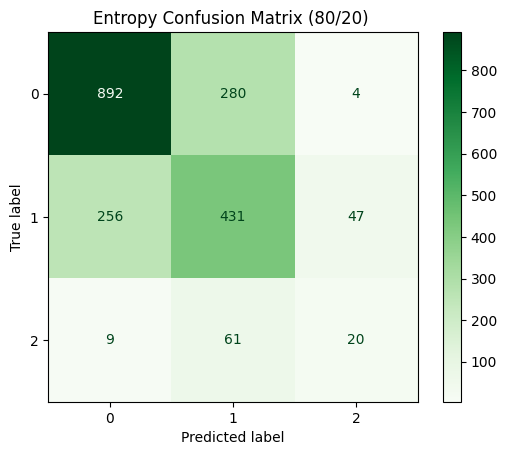

In [177]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))

cn=df['Daily_Stress_Level'].unique()
ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=cn,
    cmap="Greens"
)

plt.title("Entropy Confusion Matrix (80/20) ")
plt.show()


**Partition 70/30**

Accuracy: 0.6706666666666666
Precision: 0.669756111285869
Recall: 0.6706666666666666


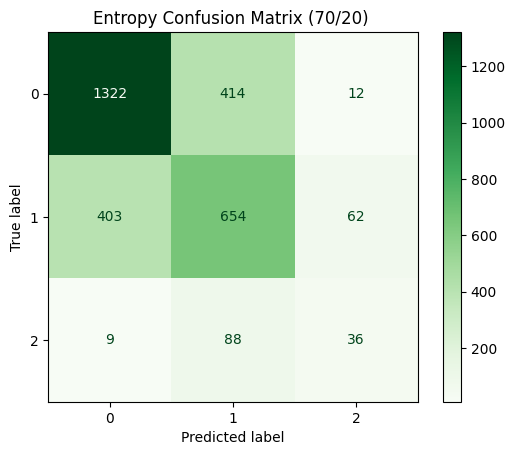

In [178]:

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))

cn=df['Daily_Stress_Level'].unique()

ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=cn,
    cmap="Greens"
)

plt.title("Entropy Confusion Matrix (70/20) ")
plt.show()

| Train/Test Split | Accuracy | High Stress Recall |
|---|---|---|
| 90/10 | 66.40% | 33.3% |
| 80/20 | 65.2% | 29.4% |
| 70/30 | 65.60% | 33.1% |

## **Results Before Merging Classes**

**Partition	Accuracy**

90/10	      66.8%

80/20	      66.8%

70/30	      67.4%


**Results Discussion :**

Based on the confusion matrices, Class 0 was classified more accurately than the other classes. In contrast, Class 2 showed a higher number of misclassifications, which may be due to class imbalance in the dataset.

### **Class Merging**

To reduce class imbalance and simplify the classification task, Class 2 was merged with Class 1, converting the problem from a three-class classification task into a binary classification task.

In [179]:
df['Daily_Stress_Level'] = df['Daily_Stress_Level'].replace({2:1})
df['Daily_Stress_Level'].value_counts()

,count
Daily_Stress_Level,
0,5789
1,4211


In [180]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

#Gini Decision Tree – After Merging High and Medium

In [181]:
# Merge Medium and High stress into one class
df_binary = df.copy()

df_binary['Daily_Stress_Level'] = df_binary['Daily_Stress_Level'].replace({
    2: 1
})

print(df_binary['Daily_Stress_Level'].value_counts())

Daily_Stress_Level
0    5789
1    4211
Name: count, dtype: int64


Gini Accuracy (90/10) - After Merging: 0.719


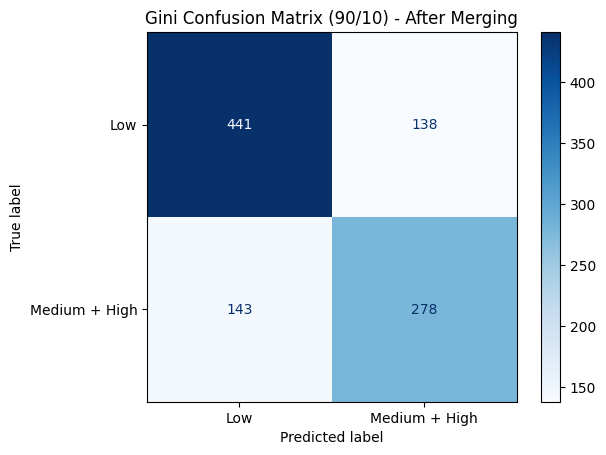

In [182]:
# Gini Decision Tree - 90/10 Split (After Merging)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_binary = df_binary.drop('Daily_Stress_Level', axis=1)
y_binary = df_binary['Daily_Stress_Level']

X_train_b90, X_test_b90, y_train_b90, y_test_b90 = train_test_split(
    X_binary, y_binary,
    test_size=0.1,
    random_state=1,
    stratify=y_binary
)

gini_b90 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b90.fit(X_train_b90, y_train_b90)

y_pred_b90 = gini_b90.predict(X_test_b90)

accuracy_b90 = accuracy_score(y_test_b90, y_pred_b90)
print("Gini Accuracy (90/10) - After Merging:", accuracy_b90)

cm_b90 = confusion_matrix(y_test_b90, y_pred_b90, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b90,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (90/10) - After Merging")
plt.show()

The Gini Decision Tree achieved 71.9% accuracy using the 90/10 split after merging Medium and High stress levels. The model correctly classified 441 Low and 278 Medium + High cases, but some predictions were still incorrect.

Gini Accuracy (80/20) - After Merging: 0.697


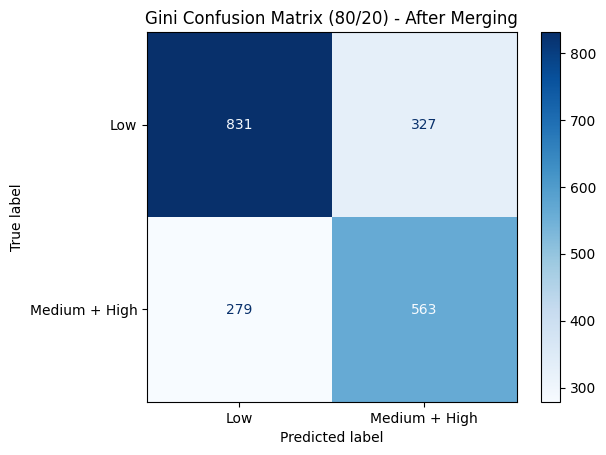

In [183]:
# Gini Decision Tree - 80/20 Split (After Merging)

X_train_b80, X_test_b80, y_train_b80, y_test_b80 = train_test_split(
    X_binary, y_binary,
    test_size=0.2,
    random_state=1,
    stratify=y_binary
)

gini_b80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b80.fit(X_train_b80, y_train_b80)

y_pred_b80 = gini_b80.predict(X_test_b80)

accuracy_b80 = accuracy_score(y_test_b80, y_pred_b80)
print("Gini Accuracy (80/20) - After Merging:", accuracy_b80)

cm_b80 = confusion_matrix(y_test_b80, y_pred_b80, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b80,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (80/20) - After Merging")
plt.show()

The Gini Decision Tree achieved **69.7% accuracy** using the 80/20 split after merging Medium and High stress levels. The model correctly classified 831 Low and 563 Medium + High cases, but some cases were still misclassified. The accuracy was slightly lower than the 90/10 split.

Gini Accuracy (70/30) - After Merging: 0.7006666666666667


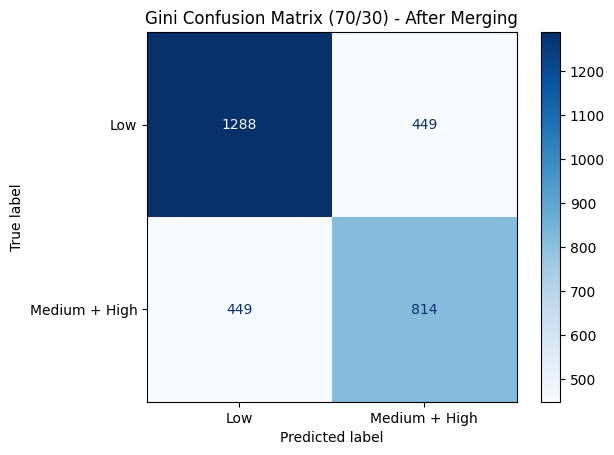

In [184]:
# Gini Decision Tree - 70/30 Split (After Merging)

X_train_b70, X_test_b70, y_train_b70, y_test_b70 = train_test_split(
    X_binary, y_binary,
    test_size=0.3,
    random_state=1,
    stratify=y_binary
)

gini_b70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b70.fit(X_train_b70, y_train_b70)

y_pred_b70 = gini_b70.predict(X_test_b70)

accuracy_b70 = accuracy_score(y_test_b70, y_pred_b70)
print("Gini Accuracy (70/30) - After Merging:", accuracy_b70)

cm_b70 = confusion_matrix(y_test_b70, y_pred_b70, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b70,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (70/30) - After Merging")
plt.show()

The Gini Decision Tree achieved **70.07% accuracy** using the 70/30 train-test split after merging Medium and High stress levels. The model correctly classified 1,288 Low and 814 Medium + High cases. However, 449 Medium + High cases were incorrectly predicted as Low. The accuracy was higher than the 80/20 split (69.7%) but lower than the 90/10 split (71.9%).

### Gini Decision Tree – Comparison Before and After Merging

| Train/Test Split | Before Merging | After Merging |
|---|---|---|
| 90/10 | 66.40% | 71.90% |
| 80/20 | 65.20% | 69.70% |
| 70/30 | 65.60% | 70.07% |

**Average Accuracy Before Merging:** 65.73%

**Average Accuracy After Merging:** 70.56%

**Improvement:** Approximately 4.82 percentage points.

### Analysis and Interpretation

The results show an improvement in overall accuracy after merging Medium and High stress levels into one class.

The average accuracy increased from 65.73% to 70.56%, representing an improvement of approximately 4.82 percentage points.

The 90/10 split achieved the highest accuracy (71.90%) after merging, followed by the 70/30 split (70.07%) and the 80/20 split (69.70%).

This improvement suggests that reducing the number of classes made the classification task easier. However, some Medium + High stress cases were still incorrectly classified as Low, indicating that the model continues to have classification limitations.

## **Decision Tree Classification Using Entropy**

The same Decision Tree classifier using the Entropy criterion was applied after merging Class 2 with Class 1 using the same train-test partitions:

90% Training  10% Testing

80% Training  20% Testing

70% Training  30% Testing


**Partition 90/10**

Accuracy: 0.726
Precision: 0.7277542666261768
Recall: 0.726


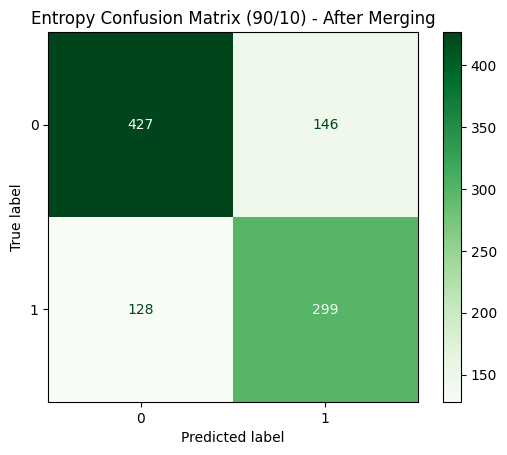

In [185]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))

cn=df['Daily_Stress_Level'].unique()
cn=df['Daily_Stress_Level'].unique()
ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=cn,
    cmap="Greens"
)

plt.title("Entropy Confusion Matrix (90/10) - After Merging")
plt.show()

**Partition 80/20**

Accuracy: 0.723
Precision: 0.7257611229783338
Recall: 0.723


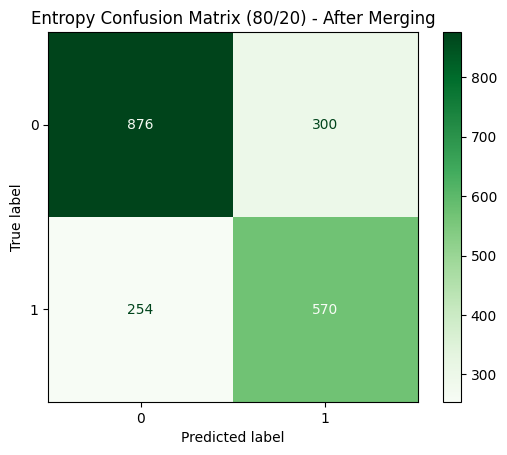

In [186]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))

cn=df['Daily_Stress_Level'].unique()
cn=df['Daily_Stress_Level'].unique()
ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=cn,
    cmap="Greens"
)

plt.title("Entropy Confusion Matrix (80/20) - After Merging")
plt.show()

**Partition 70/30**

Accuracy: 0.713
Precision: 0.7148091923675318
Recall: 0.713


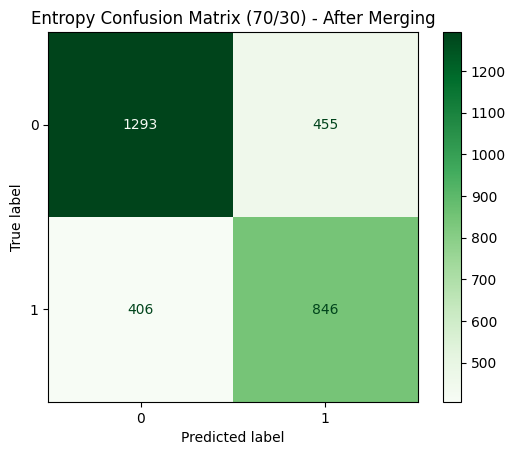

In [187]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))


cn=df['Daily_Stress_Level'].unique()
cn=df['Daily_Stress_Level'].unique()
ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=cn,
    cmap="Greens"
)

plt.title("Entropy Confusion Matrix (70/30) - After Merging")
plt.show()

## **Results After Merging Classes**


**Partition Accuracy**

70/30   71.77%

80/20   72.45%

90/10   72.90%

**Results Discussion :**

The results show an improvement across all partition sizes after merging Class 2 with Class 1. The classifier achieved higher accuracy values in all experiments, indicating that the binary classification task was easier for the model to learn. The class merging process reduced class imbalance and decreased model bias, leading to better overall performance.


## **Comparison of Results**

Partition	Before Merging	After Merging

70/30	        67.4%	        71.77%

80/20	        66.8%	        72.45%

90/10	        66.8%	        72.90%

**Average Accuracy Before Merging:** 67.0%

**Average Accuracy After Merging:** 72.37%

**Improvement:** Approximately 5.37%

## **Analysis and Interpretation**
The results show a clear improvement in performance after merging Class 2 with Class 1.

The average accuracy increased from 67.0% to 72.37%, indicating that the classifier was able to build more effective decision rules after the merge.

This improvement suggests that reducing the number of classes helped the model learn clearer decision boundaries. Additionally, merging the classes reduced class imbalance and decreased model bias, allowing the classifier to make more accurate predictions.

The highest accuracy (72.90%) was achieved using the 90/10 partition, suggesting that providing more training data improved the model's learning capability and overall performance.